# Random Forest — Dataset A (Mục 4 + 5)

**Pipeline:** Huấn luyện mô hình → Threshold trên Validation → Point estimates trên Test

**Thứ tự chạy:** Chạy `LogisticRegression.ipynb` trước để tạo `scaler.pkl`, sau đó mới chạy notebook này.

**Đầu vào cần có:** `data/processed/datasetA/{train,val,test}/<split>.csv`. Các split này không được lưu trong Git.

**Artifacts:** Notebook tạo model, metadata và figures dưới `data/processed/datasetA/results/`; các artifact này không thuộc phạm vi commit.

💡 **Lưu ý về Hyperparameters:** Sau khi dùng `GridSearchCV` chọn xong best parameters, ta truyền trực tiếp tham số vào `RandomForestClassifier(...)` để tiết kiệm thời gian chạy.

In [1]:
import sys, time, warnings, joblib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.path import DATA_DIR

DATASET_DIR = PROJECT_ROOT / "data" / "processed" / "datasetA"
RESULTS_DIR = DATASET_DIR / "results"
TABLES_DIR  = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR  = RESULTS_DIR / "models"
for d in (TABLES_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET_COL   = "action_taken"
FEATURE_COLS = ["applicant_sex","income","loan_amount","loan_purpose","lien_status","loan_type","derived_race"]
NUM_COLS     = ["income", "loan_amount"]
GROUP_NAMES  = ["applicant_race","applicant_sex","applicant_income","loan_amount","loan_purpose","lien_status","loan_type"]

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(RANDOM_STATE)
print(f"Project root : {PROJECT_ROOT}")
print(f"Results dir  : {RESULTS_DIR}")

Project root : D:\Projects\DAP391m
Results dir  : D:\Projects\DAP391m\data\processed\datasetA\results


In [2]:
from sklearn.preprocessing import StandardScaler

def load_split(name):
    df = pd.read_csv(DATASET_DIR / name / f"{name}.csv")
    return df[FEATURE_COLS].copy(), df[TARGET_COL].copy()

X_train, y_train = load_split("train")
X_val,   y_val   = load_split("val")
X_test,  y_test  = load_split("test")

print(f"Train: {len(y_train):,}  Val: {len(y_val):,}  Test: {len(y_test):,}")
print(f"Class ratio (approved/denied): {y_train.sum()}/{(~y_train.astype(bool)).sum()}")

Train: 139,671  Val: 29,930  Test: 29,930
Class ratio (approved/denied): 105821/33850


In [3]:
# Load scaler đã fit từ LR notebook
scaler = joblib.load(MODELS_DIR / "scaler.pkl")
X_train[NUM_COLS] = scaler.transform(X_train[NUM_COLS])
X_val[NUM_COLS]   = scaler.transform(X_val[NUM_COLS])
X_test[NUM_COLS]  = scaler.transform(X_test[NUM_COLS])
print("✓ Scaler loaded & applied")

✓ Scaler loaded & applied


## 1. Train Model — Random Forest

Mặc định `USE_GRID_SEARCH = False` sẽ truyền trực tiếp tham số tối ưu vào mô hình.
Nếu muốn tìm lại tham số bằng 5-fold CV, hãy đổi `USE_GRID_SEARCH = True`.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

USE_GRID_SEARCH = False  # Đổi thành True nếu muốn chạy lại GridSearchCV

# Bộ tham số tối ưu đã được xác định trước qua GridSearchCV
BEST_PARAMS_RF = {
    "n_estimators": 200,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

t0 = time.perf_counter()

if USE_GRID_SEARCH:
    print("Fitting GridSearchCV (5-fold CV)...")
    cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    param_grid = {
        "n_estimators": [100, 200],
        "max_depth": [10, 15, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
        "class_weight": ["balanced", "balanced_subsample"],
    }
    rf_grid = GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        param_grid, cv=cv_inner, scoring="roc_auc",
        refit=True, n_jobs=-1, verbose=1,
    )
    rf_grid.fit(X_train, y_train)
    rf_model = rf_grid.best_estimator_
    best_params_used = rf_grid.best_params_
    best_cv_auc = rf_grid.best_score_
    print(f"\nBest params from GridSearch: {best_params_used}")
    print(f"Best CV AUC                 : {best_cv_auc:.4f}")
else:
    print("Truyền trực tiếp best parameters vào RandomForestClassifier...")
    rf_model = RandomForestClassifier(**BEST_PARAMS_RF)
    rf_model.fit(X_train, y_train)
    best_params_used = BEST_PARAMS_RF
    best_cv_auc = None

rf_train_time = time.perf_counter() - t0
print(f"Train time: {rf_train_time:.2f}s")

Truyền trực tiếp best parameters vào RandomForestClassifier...
Train time: 2.82s


## 2. Threshold Selection — Validation set (Mục 4)

In [5]:
from sklearn.metrics import balanced_accuracy_score

def find_best_threshold(y_true, y_prob):
    """Tìm threshold tối đa hóa Balanced Accuracy (Mục 4)."""
    thresholds = np.linspace(0.01, 0.99, 99)
    best_t, best_ba = 0.5, 0.0
    for t in thresholds:
        ba = balanced_accuracy_score(y_true, (y_prob >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return round(best_t, 4), round(best_ba, 4)

rf_prob_val = rf_model.predict_proba(X_val)[:, 1]
rf_threshold, rf_ba_val = find_best_threshold(y_val.values, rf_prob_val)
print(f"RF Threshold = {rf_threshold}  (val Balanced Accuracy = {rf_ba_val})")

RF Threshold = 0.55  (val Balanced Accuracy = 0.684)


## 3. RQ1 Point Estimates — Test set (Mục 5)

In [6]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression as _LR_Cal

def calibration_intercept_slope(y_true, y_prob):
    p = np.clip(y_prob, 1e-10, 1 - 1e-10)
    logit_p = np.log(p / (1 - p)).reshape(-1, 1)
    cal = _LR_Cal(penalty=None, solver="lbfgs", max_iter=1000)
    cal.fit(logit_p, y_true)
    return float(cal.intercept_[0]), float(cal.coef_[0, 0])

def compute_rq1_metrics(y, p, t):
    yhat = (p >= t).astype(int)
    y_den = 1 - y; p_den = 1 - p
    cal_int, cal_slope = calibration_intercept_slope(y, p)
    return {
        "ROC-AUC":             roc_auc_score(y, p),
        "PR-AUC (Denied)":     average_precision_score(y_den, p_den),
        "Brier Score":         brier_score_loss(y, p),
        "Cal Intercept":       cal_int,
        "Cal Slope":           cal_slope,
        "Balanced Accuracy":   balanced_accuracy_score(y, yhat),
        "Precision (Approved)":precision_score(y, yhat, pos_label=1, zero_division=0),
        "Recall (Approved)":   recall_score(y, yhat, pos_label=1, zero_division=0),
        "F1 (Approved)":       f1_score(y, yhat, pos_label=1, zero_division=0),
        "Precision (Denied)":  precision_score(y, yhat, pos_label=0, zero_division=0),
        "Recall (Denied)":     recall_score(y, yhat, pos_label=0, zero_division=0),
        "F1 (Denied)":         f1_score(y, yhat, pos_label=0, zero_division=0),
    }

t0 = time.perf_counter()
rf_prob_test = rf_model.predict_proba(X_test)[:, 1]
rf_infer_time = time.perf_counter() - t0

rf_metrics = compute_rq1_metrics(y_test.values, rf_prob_test, rf_threshold)
print(f"\n{'Metric':<25s} {'Value':>10s}")
print("-" * 37)
for k, v in rf_metrics.items():
    print(f"{k:<25s} {v:>10.4f}")
print(f"\nTraining time : {rf_train_time:.2f}s")
print(f"Inference time: {rf_infer_time:.4f}s")


Metric                         Value
-------------------------------------
ROC-AUC                       0.7488
PR-AUC (Denied)               0.5170
Brier Score                   0.1932
Cal Intercept                 1.0473
Cal Slope                     0.9423
Balanced Accuracy             0.6768
Precision (Approved)          0.8796
Recall (Approved)             0.6179
F1 (Approved)                 0.7259
Precision (Denied)            0.3812
Recall (Denied)               0.7357
F1 (Denied)                   0.5022

Training time : 2.82s
Inference time: 0.1288s


## 4. Biểu đồ đánh giá — Random Forest

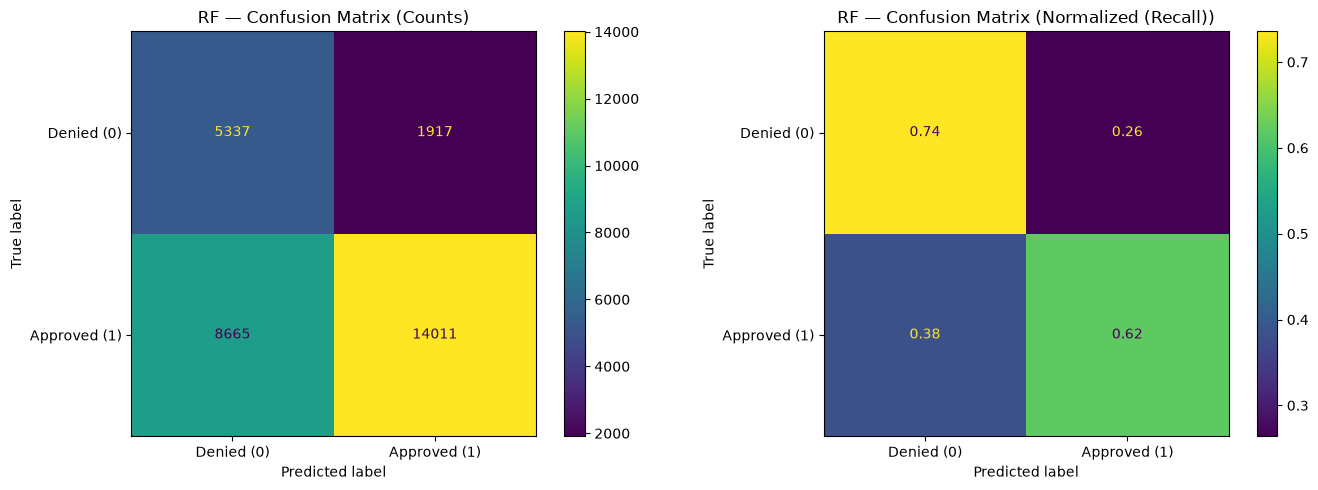

Saved


In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve

rf_pred_test = (rf_prob_test >= rf_threshold).astype(int)

# ── Confusion Matrix (counts + normalized) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, norm, title in zip(axes, [None, "true"], ["Counts", "Normalized (Recall)"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test.values, rf_pred_test, ax=ax,
        display_labels=["Denied (0)", "Approved (1)"], normalize=norm,
    )
    ax.set_title(f"RF — Confusion Matrix ({title})")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "rf_confusion_matrix.png", dpi=150)
plt.show()
print(f"Saved")

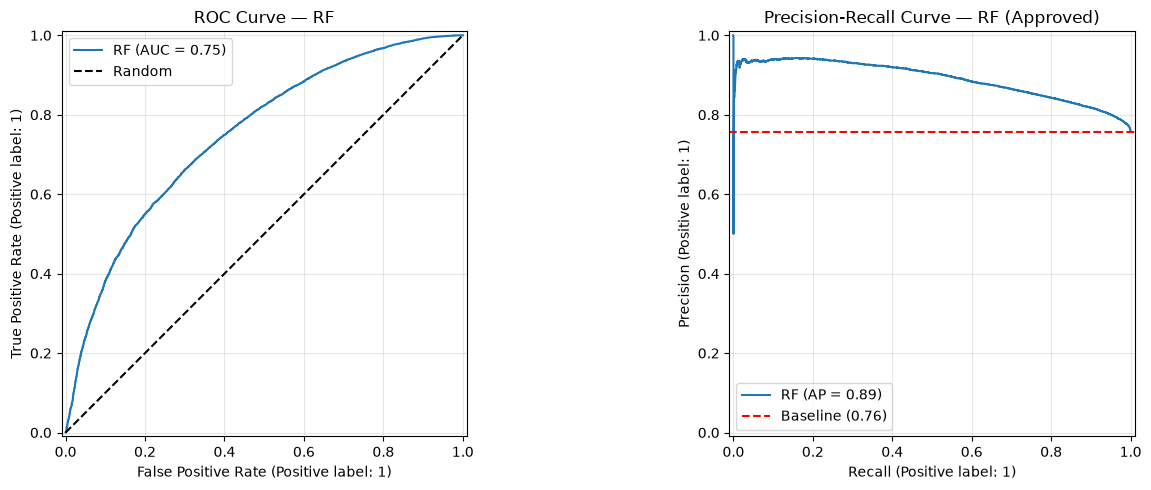

Saved


In [9]:
# ── ROC Curve + Precision-Recall Curve ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

RocCurveDisplay.from_predictions(y_test.values, rf_prob_test, ax=axes[0], name="RF")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_title("ROC Curve — RF")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

PrecisionRecallDisplay.from_predictions(y_test.values, rf_prob_test, ax=axes[1], name="RF")
baseline_pr = y_test.values.mean()
axes[1].axhline(baseline_pr, color="r", ls="--", label=f"Baseline ({baseline_pr:.2f})")
axes[1].set_title("Precision-Recall Curve — RF (Approved)")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "rf_roc_pr_curves.png", dpi=150)
plt.show()
print(f"Saved")

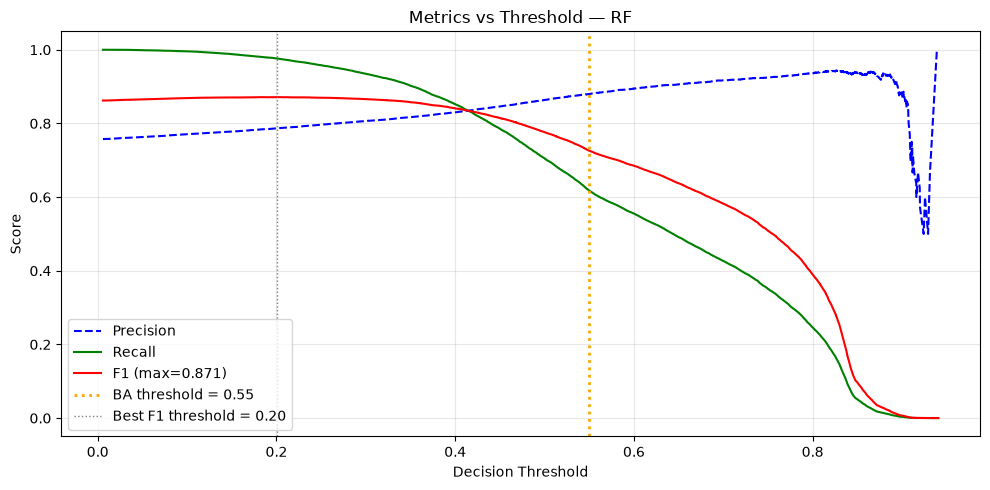

Saved


In [10]:
# ── Precision / Recall / F1 vs Threshold ──
precisions, recalls, thresholds = precision_recall_curve(y_test.values, rf_prob_test)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_f1_thresh = float(thresholds[best_idx]) if best_idx < len(thresholds) else 0.5

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, precisions[:-1], "b--", label="Precision")
ax.plot(thresholds, recalls[:-1], "g-", label="Recall")
ax.plot(thresholds, f1_scores[:-1], "r-", label=f"F1 (max={f1_scores[best_idx]:.3f})")
ax.axvline(rf_threshold, color="orange", ls=":", lw=2, label=f"BA threshold = {rf_threshold}")
ax.axvline(best_f1_thresh, color="gray", ls=":", lw=1, label=f"Best F1 threshold = {best_f1_thresh:.2f}")
ax.set_xlabel("Decision Threshold"); ax.set_ylabel("Score")
ax.set_title("Metrics vs Threshold — RF")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "rf_threshold_analysis.png", dpi=150)
plt.show()
print(f"Saved")

## 5. Lưu model + threshold

In [11]:
joblib.dump(rf_model, MODELS_DIR / "rf_model.pkl")
joblib.dump({
    "threshold": rf_threshold,
    "train_time": rf_train_time,
    "infer_time": rf_infer_time,
    "best_params": best_params_used,
    "best_cv_auc": best_cv_auc,
}, MODELS_DIR / "rf_meta.pkl")

print("✅ Random Forest — HOÀN TẤT!")
print(f"   Model    → {MODELS_DIR / 'rf_model.pkl'}")
print(f"   Metadata → {MODELS_DIR / 'rf_meta.pkl'}")
print(f"   Figures  → {list(FIGURES_DIR.glob('rf_*.png'))}")

✅ Random Forest — HOÀN TẤT!
   Model    → D:\Projects\DAP391m\data\processed\datasetA\results\models\rf_model.pkl
   Metadata → D:\Projects\DAP391m\data\processed\datasetA\results\models\rf_meta.pkl
   Figures  → [WindowsPath('D:/Projects/DAP391m/data/processed/datasetA/results/figures/rf_confusion_matrix.png'), WindowsPath('D:/Projects/DAP391m/data/processed/datasetA/results/figures/rf_roc_pr_curves.png'), WindowsPath('D:/Projects/DAP391m/data/processed/datasetA/results/figures/rf_threshold_analysis.png')]
